In [1]:
# conda vis2
from pathlib import Path
PROJECT_ROOT = Path().resolve().parent.parent.parent

import sys
sys.path.append(str(PROJECT_ROOT))

from src.utils.util import load_config
import xarray as xr
import matplotlib.pyplot as plt

In [2]:
savefigs = True

EXPERIMENT = PROJECT_ROOT / 'experiments' / 'CAMP2Ex_RF17' / 'V08' / 'default'
FIGURE_OUT = EXPERIMENT / 'figures'
FIGURE_OUT.mkdir(parents=True, exist_ok=True)

config = load_config(EXPERIMENT / 'config.yml')

cvm = xr.load_dataset(config['cloud_volume_mask_file'])

## Figure: Cloud Volume Mask

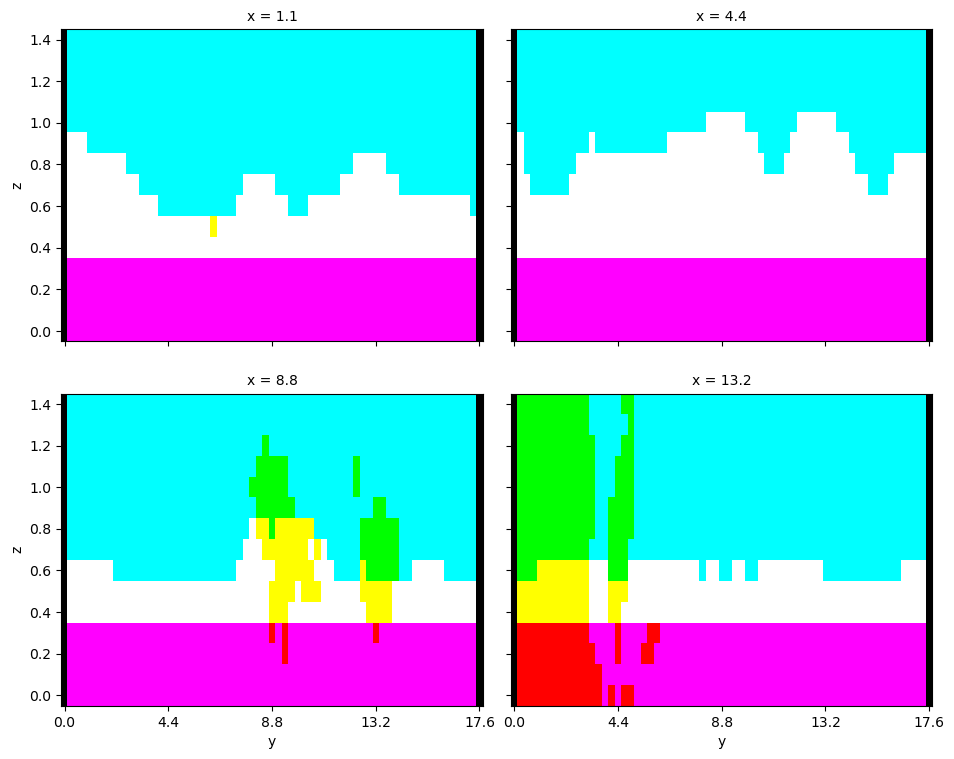

In [3]:
ticks = [0.0, 4.4, 8.8, 13.2, 17.6]
# facetgrid = cvm.rbg_mask.isel(x=slice(4,64,4)).plot.imshow(x='y', y='z', col='x', col_wrap=5)
facetgrid = cvm.rbg_mask.isel(x=[4, 16, 32, 48]).plot.imshow(x='y', y='z', col='x', col_wrap=2)

for ax in facetgrid.axes.flatten():
    ax.set_xticks(ticks)
facetgrid.fig.set_size_inches(10, 8)

if(savefigs):
    plt.savefig(
        FIGURE_OUT / 'CVM.png',
        format='png',
        dpi=300,
        bbox_inches='tight',
        transparent=False
    )